# Previsão diária de aluguéis com LSTM
**Equipe:** Felipe Vieira Brazão e João Ricardo Almeida  
**Disciplina:** Inteligência Computacional / Machine Learning  
**Professora:** Polyana Santos Fonseca Nascimento

## Transparência no uso de IA generativa
Foi utilizado o ChatGPT/Codex, da OpenAI, para  pesquisar a fonte dos dados , elaborar a estrutura, os textos e suporte no código deste notebook. A equipe realizou a função de revisar, executar e compreender o material antes da entrega. Foram feitas verificações de sintaxe e do protocolo de separação temporal; a execução completa do treinamento e a conferência dos resultados pela dupla. Não se apresentam métricas inventadas.

**Como executar:** abra este arquivo no Google Colab (Arquivo > Fazer upload de notebook) e use Ambiente de execução > Executar tudo. A primeira execução requer internet para baixar a base. Se necessário, instale as dependências indicadas na primeira célula. Salve a versão com todas as saídas. É obrigatório participar de pelo menos um encontro de acompanhamento antes da entrega; registrem a data real após participar.

## 1. Ambiente e reprodutibilidade
Usamos TensorFlow/Keras, NumPy, pandas e Matplotlib, normalmente disponíveis no Colab. Se um import falhar, executem em uma célula: `%pip install tensorflow numpy pandas matplotlib`. As versões efetivas são registradas abaixo. A semente reduz variações, mas hardware e versões podem afetar o treinamento.

**Execução local no Windows:** selecione o kernel **Python (LSTM - projeto)**, que usa o ambiente `.venv` desta pasta. Para executar tudo pelo terminal, use `.\.venv\Scripts\python.exe executar_notebook.py`. As saídas são salvas neste notebook e os arquivos do experimento em `resultados_lstm/`.

In [1]:
import os, io, zipfile, urllib.request, hashlib, json
from pathlib import Path
os.environ['TF_DETERMINISTIC_OPS'] = '1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown
SEED=42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
PASTA=Path('resultados_lstm'); PASTA.mkdir(exist_ok=True)
versoes={'tensorflow':tf.__version__, 'numpy':np.__version__, 'pandas':pd.__version__}
print(versoes)

{'tensorflow': '2.21.0', 'numpy': '2.5.4', 'pandas': '3.1.1'}


## 2. Dataset, problema e variável-alvo
Utilizamos o arquivo **day.csv**, do [Bike Sharing Dataset da UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), de Hadi Fanaee-T. A série registra aluguéis diários do sistema Capital Bikeshare em 2011 e 2012. O alvo é **cnt**, total de aluguéis por dia. O objetivo é prever o total do próximo dia usando apenas totais anteriores, com horizonte de um passo.

A base permite estudar dependências temporais em um problema de mobilidade. O uso exclusivo do histórico evita depender de informações meteorológicas futuras. As colunas casual e registered não entram no modelo: sua soma compõe o alvo do próprio dia. A frequência é diária. A referência semanal é uma hipótese justificável pela diferença entre dias úteis e fins de semana; não se pressupõe que seja superior à persistência.

SHA256 day.csv: a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be
Observações: 731 | Período: 2011-01-01 00:00:00 a 2012-12-31 00:00:00


,Aluguéis por dia
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


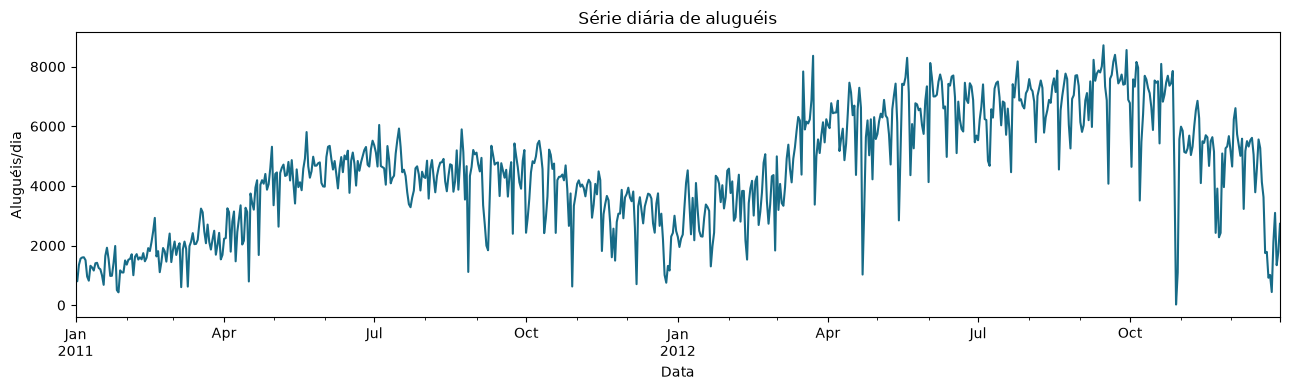

In [2]:
URL='https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
arquivo=Path('day.csv')
if not arquivo.exists():
    with urllib.request.urlopen(URL, timeout=90) as r:
        conteudo=r.read()
    with zipfile.ZipFile(io.BytesIO(conteudo)) as z:
        nome=next(n for n in z.namelist() if n.split('/')[-1]=='day.csv')
        arquivo.write_bytes(z.read(nome))
print('SHA256 day.csv:',hashlib.sha256(arquivo.read_bytes()).hexdigest())
df=pd.read_csv(arquivo,parse_dates=['dteday']).sort_values('dteday')
assert not df['dteday'].duplicated().any(), 'Datas duplicadas: investigar antes de continuar.'
serie=df.set_index('dteday')['cnt'].asfreq('D')
assert serie.notna().all(), 'Há lacunas: investigar sem interpolar com dados futuros.'
assert (serie>=0).all()
print('Observações:',len(serie),'| Período:',serie.index.min(), 'a',serie.index.max())
display(serie.describe().to_frame('Aluguéis por dia'))
fig,ax=plt.subplots(figsize=(13,4))
serie.plot(ax=ax,color='#176b87',title='Série diária de aluguéis')
ax.set(xlabel='Data',ylabel='Aluguéis/dia'); plt.tight_layout(); plt.show()

### Ordem cronológica e lacunas
Ordenamos as datas e verificamos duplicatas, valores ausentes e ausência de dias no calendário. O arquivo original deve passar nessas verificações sem imputação. Caso a fonte seja alterada e apareçam lacunas, o código interrompe a execução para investigação; não utiliza interpolação que consulte valores futuros.

## 3. Partições e normalização
Reservamos os últimos 20% da série (arredondados para cima) para teste, os 20% anteriores para validação e o início para treino. As partições usam a **data do alvo**. Os primeiros 28 dias fornecem contexto e não são alvos em nenhuma das duas configurações. Assim, todas as datas-alvo de treino, validação e teste são idênticas para as janelas de 7 e 28 dias.

A padronização usa média e desvio padrão somente do trecho de treino, incluindo seu contexto inicial. As previsões são reconvertidas a aluguéis/dia antes de calcular o MAE. Um alvo de validação ou teste pode usar observações reais anteriores já disponíveis: a avaliação representa previsões diárias sucessivas de um passo, com atualização do histórico, e não uma previsão de todo o período de uma só vez.

In [3]:
JANELAS=(7,28)
valores=serie.to_numpy(dtype=np.float32)
n=len(valores); n_teste=int(np.ceil(0.20*n)); n_val=int(np.ceil(0.20*n))
fim_treino=n-n_val-n_teste; inicio_teste=n-n_teste
assert fim_treino>max(JANELAS)
alvos=np.arange(max(JANELAS),n)
mascaras={'treino':alvos<fim_treino,
          'validacao':(alvos>=fim_treino)&(alvos<inicio_teste),
          'teste':alvos>=inicio_teste}
media=float(valores[:fim_treino].mean())
desvio=float(valores[:fim_treino].std())
assert desvio>0
z=(valores-media)/desvio
def criar_janelas(w):
    X=np.stack([z[t-w:t] for t in alvos])[...,None]
    y=z[alvos]
    assert X.shape==(len(alvos),w,1)
    return {p:(X[m],y[m]) for p,m in mascaras.items()}
dados={w:criar_janelas(w) for w in JANELAS}
resumo=[]
for p,m in mascaras.items():
    datas=serie.index[alvos[m]]
    resumo.append({'particao':p,'alvos':len(datas),'inicio':str(datas.min().date()),'fim':str(datas.max().date())})
    assert len(dados[7][p][1])==len(dados[28][p][1])
    np.testing.assert_array_equal(dados[7][p][1],dados[28][p][1])
assert mascaras['teste'].sum()/n>=0.20
display(pd.DataFrame(resumo))

,particao,alvos,inicio,fim
0,treino,409,2011-01-29,2012-03-12
1,validacao,147,2012-03-13,2012-08-06
2,teste,147,2012-08-07,2012-12-31


## 4. Janelas e arquitetura LSTM
A janela de **7 dias** contém uma semana; a de **28 dias**, quatro semanas. Ambas avançam um dia de cada vez. Para prever o dia t, a entrada termina em t-1; o valor do dia t nunca entra na própria entrada. A janela é deslizante de tamanho fixo, conforme a distinção do material de apoio, e não crescente.

Mantemos a mesma arquitetura: LSTM de 32 unidades, camada densa de 16 unidades com ReLU e saída linear de uma unidade. O otimizador é Adam (0,001), a perda é MAE, o lote é 32, o limite é 100 épocas e a parada antecipada tem paciência de 12 épocas, restaurando os melhores pesos. O número efetivo de épocas pode variar pela mesma regra de parada. Não embaralhamos os exemplos. Não reajustamos a configuração após consultar o teste.

In [4]:
def modelo_lstm(w):
    modelo=tf.keras.Sequential([
        tf.keras.Input(shape=(w,1)),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16,activation='relu'),
        tf.keras.layers.Dense(1)])
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='mae')
    return modelo
def mae(real,pred):
    return float(np.mean(np.abs(np.asarray(real)-np.asarray(pred))))
modelos={}; historicos={}; linhas=[]
for w in JANELAS:
    tf.keras.utils.set_random_seed(SEED)
    modelo=modelo_lstm(w)
    Xtr,ytr=dados[w]['treino']; Xv,yv=dados[w]['validacao']
    parada=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=12,restore_best_weights=True)
    hist=modelo.fit(Xtr,ytr,validation_data=(Xv,yv),epochs=100,batch_size=32,
                    shuffle=False,callbacks=[parada],verbose=0)
    pred=modelo.predict(Xv,verbose=0).ravel()*desvio+media
    linhas.append({'janela_dias':w,'MAE_validacao':mae(valores[alvos[mascaras['validacao']]],pred),
                   'epocas':len(hist.history['loss'])})
    modelos[w]=modelo; historicos[w]=hist.history
    print('Treinamento concluído:',w,'dias')
tabela_val=pd.DataFrame(linhas).sort_values(['MAE_validacao','janela_dias']).reset_index(drop=True)
escolhida=int(tabela_val.iloc[0]['janela_dias'])
tabela_val['escolhida']=tabela_val['janela_dias'].eq(escolhida)
display(tabela_val)
tabela_val.to_csv(PASTA/'validacao.csv',index=False)
print('Janela escolhida exclusivamente pela validação:',escolhida)

Treinamento concluído: 7 dias


Treinamento concluído: 28 dias


,janela_dias,MAE_validacao,epocas,escolhida
0,7,1342.928955,20,True
1,28,1405.344360,33,False


Janela escolhida exclusivamente pela validação: 7


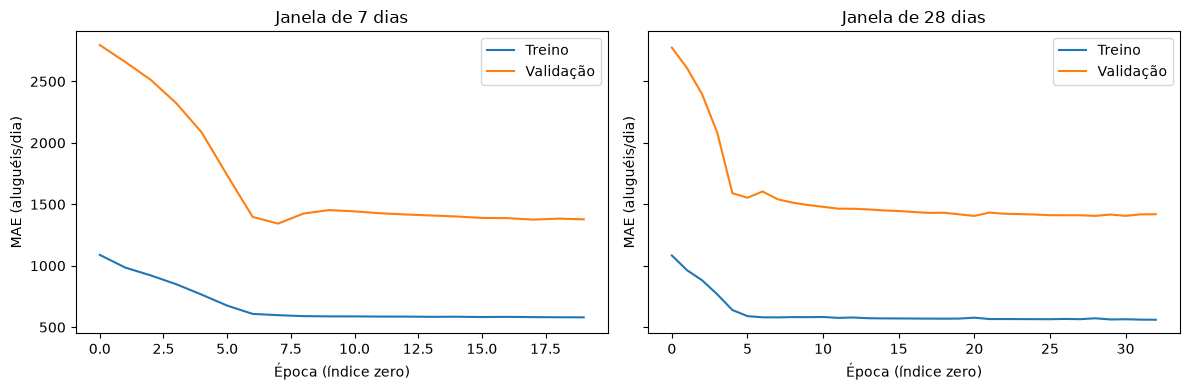

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,w in zip(axes,JANELAS):
    ax.plot(np.array(historicos[w]['loss'])*desvio,label='Treino')
    ax.plot(np.array(historicos[w]['val_loss'])*desvio,label='Validação')
    ax.set(title=f'Janela de {w} dias',xlabel='Época (índice zero)',ylabel='MAE (aluguéis/dia)')
    ax.legend()
plt.tight_layout(); plt.show()

## 5. Teste: LSTM selecionada e referências
Usamos o modelo selecionado sem novo treinamento. A **persistência** prevê y(t-1); a **referência semanal** prevê y(t-7). Todas são avaliadas nas mesmas datas e na escala original. Não arredondamos nem cortamos as previsões da LSTM. O MAE expressa o desvio absoluto médio em aluguéis diários; quanto menor, melhor.

,metodo,MAE_teste
1,Persistência,878.394531
2,Sazonal semanal,1194.734741
0,LSTM,1481.338867


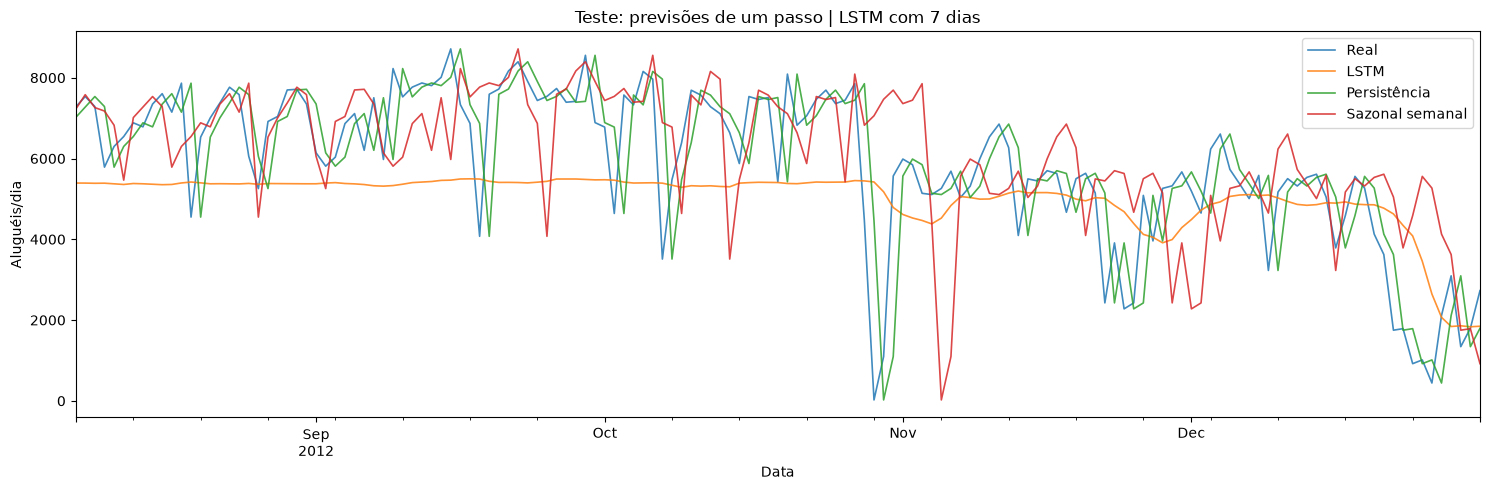

309

In [6]:
idx=alvos[mascaras['teste']]
Xt,_=dados[escolhida]['teste']
previsoes=pd.DataFrame({'Real':valores[idx],
    'LSTM':modelos[escolhida].predict(Xt,verbose=0).ravel()*desvio+media,
    'Persistência':valores[idx-1], 'Sazonal semanal':valores[idx-7]},index=serie.index[idx])
tabela_teste=pd.DataFrame([{'metodo':m,'MAE_teste':mae(previsoes['Real'],previsoes[m])}
    for m in previsoes.columns if m!='Real']).sort_values('MAE_teste')
display(tabela_teste)
fig,ax=plt.subplots(figsize=(15,5))
previsoes.plot(ax=ax,linewidth=1.2,alpha=0.85)
ax.set(title=f'Teste: previsões de um passo | LSTM com {escolhida} dias',xlabel='Data',ylabel='Aluguéis/dia')
plt.tight_layout(); plt.savefig(PASTA/'previsoes_teste.png',dpi=160); plt.show()
previsoes.to_csv(PASTA/'previsoes_teste.csv',index_label='data')
tabela_teste.to_csv(PASTA/'teste.csv',index=False)
modelos[escolhida].save(PASTA/'lstm_selecionada.keras')
(PASTA/'configuracao.json').write_text(json.dumps({'seed':SEED,'janelas':JANELAS,
    'janela_escolhida':escolhida,'media_treino':media,'desvio_treino':desvio,
    'fim_treino_posicao_exclusiva':fim_treino,'inicio_teste_posicao':inicio_teste,
    'versoes':versoes},indent=2),encoding='utf-8')

## 6. Conclusão baseada nos resultados
A próxima célula produz uma síntese numérica a partir da execução real. A dupla deve complementá-la com a leitura do gráfico: os picos foram acompanhados? Houve atraso nas mudanças? Quais intervalos concentraram erros? Uma janela maior não garante melhor desempenho, e uma rede mais complexa pode perder para referências simples. O experimento usa uma única divisão cronológica e uma semente; portanto, não demonstra superioridade geral nem mede estabilidade estatística.

In [7]:
v=tabela_val.set_index('janela_dias')['MAE_validacao']
t=tabela_teste.set_index('metodo')['MAE_teste']
efeito='reduziu' if v.loc[28]<v.loc[7] else ('aumentou' if v.loc[28]>v.loc[7] else 'não alterou')
texto=f'A janela de 28 dias {efeito} o MAE de validação: 7 dias = {v.loc[7]:.2f}; 28 dias = {v.loc[28]:.2f} aluguéis/dia. A janela selecionada foi de {escolhida} dias.'
for ref in ['Persistência','Sazonal semanal']:
    rel='menor' if t['LSTM']<t[ref] else ('maior' if t['LSTM']>t[ref] else 'igual')
    texto+=f' No teste, o MAE da LSTM ({t["LSTM"]:.2f}) foi {rel} que o de {ref} ({t[ref]:.2f}).'
display(Markdown(texto))
(PASTA/'conclusao.txt').write_text(texto,encoding='utf-8')

A janela de 28 dias aumentou o MAE de validação: 7 dias = 1342.93; 28 dias = 1405.34 aluguéis/dia. A janela selecionada foi de 7 dias. No teste, o MAE da LSTM (1481.34) foi maior que o de Persistência (878.39). No teste, o MAE da LSTM (1481.34) foi maior que o de Sazonal semanal (1194.73).

290


## Referências
- Fanaee-T, H. Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894
- TensorFlow. LSTM: https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM
- TensorFlow. EarlyStopping: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping
- Lauda LSTM 2026_2 e Janelas de entrada para LSTM: materiais fornecidos na atividade.